<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup](README.md)

# 01 · Does a changed scan string mean the label failed?

A label check that compares only strings can reject a valid representation change. In this worker, EAN-13 with a leading zero can scan as UPC-A with that one zero omitted. Conversely, removing leading zeros from every label can hide a real mismatch.

We will generate nine **synthetic test labels** through the published barcode worker, decode their PNGs, and separate exact matches, a narrowly defined EAN/UPC equivalence, and failures. Then we will change the requested image size and compare actual dimensions, PNG bytes and decode results. These are digital round trips through one library, not a print-quality or physical-scanner test.

## Choose a requested pixel size

`SIZE_PX` is a requested width (and a square-size request for QR), from 64 to 512 in this bounded example. The encoder can enforce minimum symbol dimensions, so inspect the actual PNG header rather than assuming the request is exact.

The experiment changes only **256 → 128 pixels**. Predict smaller images or PNG files while keeping payload identities. A prediction is not a guarantee: symbol geometry and PNG compression affect the result. Restart the kernel and Run All after changing the parameter.

In [1]:
SIZE_PX = 256  # Integer 64–512 requested pixels; experiment: 128

In [2]:
import hashlib
from io import BytesIO

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from IPython.display import Markdown, display

assert isinstance(SIZE_PX,int) and not isinstance(SIZE_PX,bool) and 64 <= SIZE_PX <= 512
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":125,"text.parse_math":False,"axes.spines.top":False,"axes.spines.right":False})
COLORS={"EAN_13":"#247f9e","CODE_128":"#745b9e","QR_CODE":"#b88a29"}
def prose(text):display(Markdown(text))
def finish(fig):
    fig.text(.01,.01,f"Source: synthetic payloads · published vgi-barcode v0.4.0 · requested {SIZE_PX} px · digital round trip",fontsize=8,color="#555555")
    fig.tight_layout(rect=(0,.06,1,.93));plt.show()
con=haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline


/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-barcode/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-barcode/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-barcode/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-barcode/notebooks/pyproject.toml.

## Attach the published worker and discover formats

The literal release location downloads the native worker for the current platform. No local worker build or checkout is needed. Encoding and decoding both use its rxing implementation, so success here checks software agreement; it is not an independent certification of a physical label.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'barcode' AS barcode (
    TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-barcode@v0.4.0'
);

,Success


In [4]:
%%sql formats <<
SELECT format FROM barcode.main.barcode_formats() ORDER BY format;

In [5]:
display(formats)

,format
0,AZTEC
1,CODABAR
2,CODE_128
3,CODE_39
4,CODE_93
5,DATA_MATRIX
6,EAN_13
7,EAN_8
8,ITF
9,PDF_417


## Generate a fixed set of test labels once

Payloads stay as text. Their leading zeros and Unicode characters are part of the input. The three EAN examples have valid check digits; their use here does not assert ownership of a product identifier. The QR URL uses the reserved example domain and is never fetched.

Format and image size are bind-time constants, so each SQL branch generates one symbology. Materialize the PNGs before decoding or plotting them.

In [6]:
%%sql
CREATE TABLE labels AS
SELECT label_id,'EAN_13' AS requested_format,payload,
       barcode.main.generate_barcode(payload,'EAN_13',{{SIZE_PX}}) AS png
FROM (VALUES ('ean-standard','5901234123457'),('ean-second','4006381333931'),
             ('ean-upc-equivalent','0036000291452')) t(label_id,payload)
UNION ALL
SELECT label_id,'CODE_128',payload,
       barcode.main.generate_barcode(payload,'CODE_128',{{SIZE_PX}})
FROM (VALUES ('code-parcel','PARCEL-0007'),('code-sku','SKU-000042'),
             ('code-leading-zero','000123')) t(label_id,payload)
UNION ALL
SELECT label_id,'QR_CODE',payload,barcode.main.generate_qr(payload,{{SIZE_PX}})
FROM (VALUES ('qr-parcel','synthetic:parcel/0007'),
             ('qr-url','https://example.org/labels/000042'),
             ('qr-unicode','Batch café — 2026')) t(label_id,payload);

CREATE TABLE decoded AS
SELECT label_id,requested_format,payload,octet_length(png) AS png_bytes,
       barcode.main.decode_barcode(png) AS scanned_text,
       barcode.main.barcode_format(png) AS scanned_format
FROM labels;

,Count


## Compare exact identity before applying one explicit equivalence

An exact match requires both the original payload and requested format. The **only** normalization allowed here applies when all of these conditions hold: requested format EAN-13, 13 decimal digits beginning with zero, detected format UPC-A, and 12 decimal decoded digits. Prepending exactly one zero must then recover the original payload.

We do not cast identifiers to numbers or strip arbitrary zeros. A missing decode remains `No decode`; a different decoded value stays `Mismatch`.

In [7]:
%%sql
CREATE TABLE qa AS
SELECT *,
       CASE WHEN scanned_text IS NULL THEN 'No decode'
            WHEN scanned_text=payload AND scanned_format=requested_format THEN 'Exact match'
            WHEN requested_format='EAN_13' AND scanned_format='UPC_A'
                 AND regexp_full_match(payload,'0[0-9]{12}')
                 AND regexp_full_match(scanned_text,'[0-9]{12}')
                 AND '0'||scanned_text=payload THEN 'EAN/UPC equivalent'
            ELSE 'Mismatch' END AS outcome
FROM decoded;

,Count


In [8]:
%%sql results <<
SELECT label_id,requested_format,payload,scanned_format,scanned_text,outcome,png_bytes
FROM qa ORDER BY requested_format,label_id;

In [9]:
%%sql outcome_counts <<
SELECT requested_format,outcome,count(*) AS labels
FROM qa GROUP BY ALL ORDER BY requested_format,outcome;

In [10]:
display(results);display(outcome_counts)
assert results.label_id.is_unique and (results.png_bytes>0).all()
assert results.loc[results.outcome=="Exact match","payload"].equals(results.loc[results.outcome=="Exact match","scanned_text"])
counts=results.outcome.value_counts()
exact=int(counts.get("Exact match",0));equivalent=int(counts.get("EAN/UPC equivalent",0));missing=int(counts.get("No decode",0));mismatch=int(counts.get("Mismatch",0))
payloads=con.execute("SELECT label_id,requested_format,payload FROM labels ORDER BY label_id").fetchall()
input_hash=hashlib.sha256(repr(payloads).encode()).hexdigest()
prose(f"At **{SIZE_PX} requested pixels**, the {len(results)} synthetic labels yield **{exact} exact matches**, "
      f"**{equivalent} EAN/UPC equivalents**, **{missing} missing decodes** and **{mismatch} mismatches**. "
      f"A strict text-and-format gate would reject {len(results)-exact}; the explicit equivalence rule accepts {equivalent} of those. "
      f"**Payload fingerprint:** `{input_hash}`. This fingerprint excludes image size so the experiment can verify unchanged inputs.")

,label_id,requested_format,payload,scanned_format,scanned_text,outcome,png_bytes
0,code-leading-zero,CODE_128,000123,CODE_128,000123,Exact match,380
1,code-parcel,CODE_128,PARCEL-0007,CODE_128,PARCEL-0007,Exact match,374
2,code-sku,CODE_128,SKU-000042,CODE_128,SKU-000042,Exact match,367
3,ean-second,EAN_13,4006381333931,EAN_13,4006381333931,Exact match,380
4,ean-standard,EAN_13,5901234123457,EAN_13,5901234123457,Exact match,381
5,ean-upc-equivalent,EAN_13,0036000291452,UPC_A,036000291452,EAN/UPC equivalent,381
6,qr-parcel,QR_CODE,synthetic:parcel/0007,QR_CODE,synthetic:parcel/0007,Exact match,1484
7,qr-unicode,QR_CODE,Batch café — 2026,QR_CODE,Batch café — 2026,Exact match,1477
8,qr-url,QR_CODE,https://example.org/labels/000042,QR_CODE,https://example.org/labels/000042,Exact match,1631


,requested_format,outcome,labels
0,CODE_128,Exact match,3
1,EAN_13,EAN/UPC equivalent,1
2,EAN_13,Exact match,2
3,QR_CODE,Exact match,3


At **256 requested pixels**, the 9 synthetic labels yield **8 exact matches**, **1 EAN/UPC equivalents**, **0 missing decodes** and **0 mismatches**. A strict text-and-format gate would reject 1; the explicit equivalence rule accepts 1 of those. **Payload fingerprint:** `ad64c511eee0e966730e41ae8b32c415e6d808aa93ad3945c14ce61b738bd9fa`. This fingerprint excludes image size so the experiment can verify unchanged inputs.

## Inspect the images behind the comparison

The preview deliberately includes the EAN/UPC case, a Code 128 value with leading zeros, and a Unicode QR payload. Images are displayed at convenient sizes with nearest-neighbor interpolation; the screen preview is not their physical print size. The dimensions in each caption come from the actual PNG header.

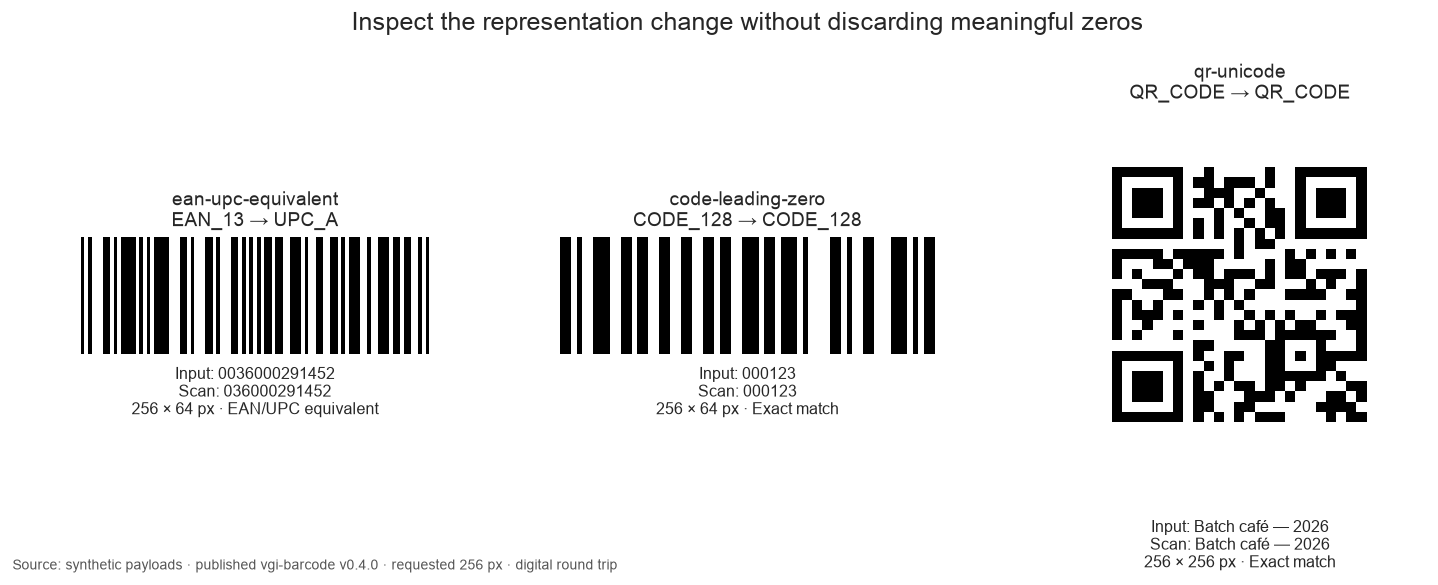

In [11]:
images=con.execute("SELECT label_id,png FROM labels ORDER BY label_id").fetchall()
image_map={name:Image.open(BytesIO(bytes(blob))).copy() for name,blob in images}
measurements=pd.DataFrame([{"label_id":name,"width_px":image_map[name].width,"height_px":image_map[name].height} for name,_ in images])
con.register("png_header_frame",measurements)
con.execute("CREATE TABLE png_dimensions AS SELECT * FROM png_header_frame")
con.unregister("png_header_frame")
chosen=["ean-upc-equivalent","code-leading-zero","qr-unicode"]
fig,axes=plt.subplots(1,3,figsize=(12,4.6))
for ax,name in zip(axes,chosen):
    row=results.set_index("label_id").loc[name];img=image_map[name]
    ax.imshow(img,cmap="gray",vmin=0,vmax=255,interpolation="nearest");ax.grid(False);ax.axis("off")
    ax.set_title(f"{name}\n{row.requested_format} → {row.scanned_format}",fontsize=11)
    ax.text(.5,-.10,f"Input: {row.payload}\nScan: {row.scanned_text}\n{img.width} × {img.height} px · {row.outcome}",ha="center",va="top",transform=ax.transAxes,fontsize=9)
fig.suptitle("Inspect the representation change without discarding meaningful zeros");finish(fig)

## Measure actual dimensions and storage

PNG byte count includes compression and image structure, so it is not a direct measure of information capacity or scanning reliability. Use the same payload set when comparing image sizes. SQL joins header measurements back to the worker-generated PNG byte counts and decode outcomes.

In [12]:
%%sql measurements <<
SELECT q.label_id,q.requested_format,d.width_px,d.height_px,q.png_bytes,q.outcome
FROM qa q JOIN png_dimensions d USING (label_id)
ORDER BY q.requested_format,q.label_id;

,label_id,requested_format,width_px,height_px,png_bytes,outcome
0,code-leading-zero,CODE_128,256,64,380,Exact match
1,code-parcel,CODE_128,256,64,374,Exact match
2,code-sku,CODE_128,256,64,367,Exact match
3,ean-second,EAN_13,256,64,380,Exact match
4,ean-standard,EAN_13,256,64,381,Exact match
5,ean-upc-equivalent,EAN_13,256,64,381,EAN/UPC equivalent
6,qr-parcel,QR_CODE,256,256,1484,Exact match
7,qr-unicode,QR_CODE,256,256,1477,Exact match
8,qr-url,QR_CODE,256,256,1631,Exact match


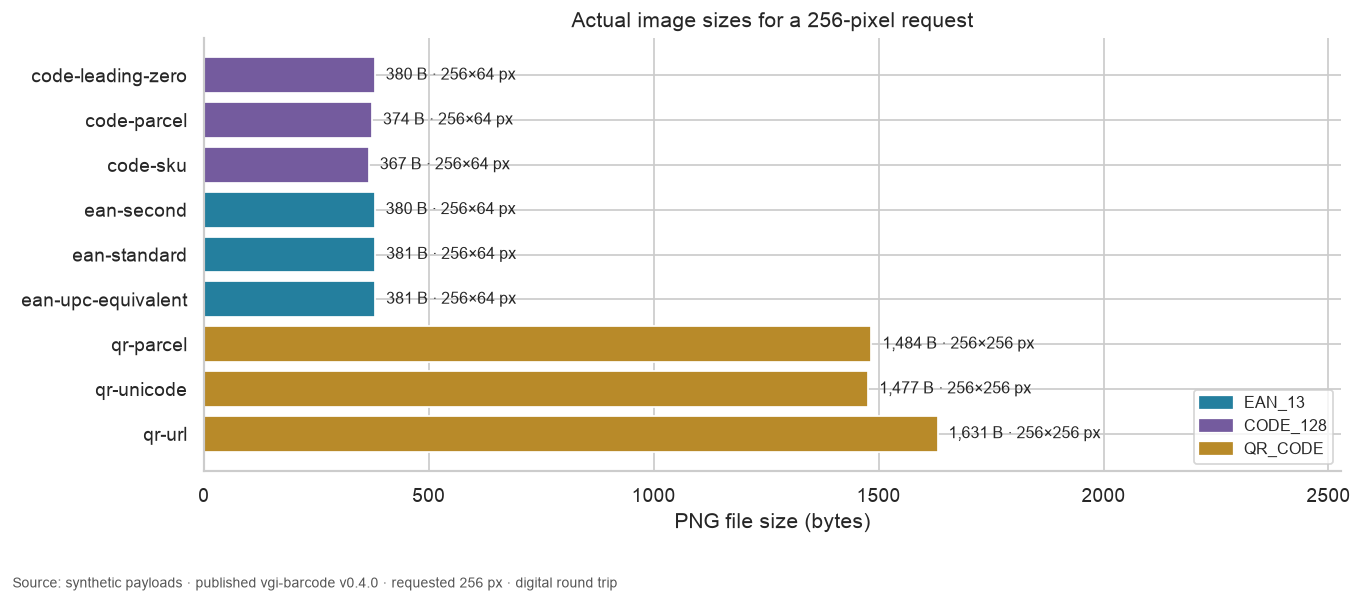

The generated PNGs occupy **6,855 bytes** in total. Actual widths range from **256 to 256 pixels**. These measurements describe this payload set and encoder version; compare them with the separate experiment, not a universal compression rule.

In [13]:
display(measurements)
assert len(measurements)==len(results) and (measurements.width_px>0).all() and (measurements.height_px>0).all()
fig,ax=plt.subplots(figsize=(11,5.2));y=np.arange(len(measurements))
ax.barh(y,measurements.png_bytes,color=[COLORS[f] for f in measurements.requested_format])
ax.set_yticks(y,measurements.label_id);ax.invert_yaxis()
for i,row in measurements.iterrows():
    ax.text(row.png_bytes+measurements.png_bytes.max()*.015,i,f"{int(row.png_bytes):,} B · {int(row.width_px)}×{int(row.height_px)} px",va="center",fontsize=9)
ax.set(xlabel="PNG file size (bytes)",xlim=(0,measurements.png_bytes.max()*1.55),
       title=f"Actual image sizes for a {SIZE_PX}-pixel request")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=color,label=fmt) for fmt,color in COLORS.items()],loc="lower right",fontsize=9);finish(fig)
prose(f"The generated PNGs occupy **{int(measurements.png_bytes.sum()):,} bytes** in total. "
      f"Actual widths range from **{int(measurements.width_px.min())} to {int(measurements.width_px.max())} pixels**. "
      "These measurements describe this payload set and encoder version; compare them with the separate experiment, not a universal compression rule.")

## Keep missing input distinct from an unsuccessful decode

The worker maps malformed image bytes and an image with no detectable code to the same NULL decode result. Therefore NULL alone does not identify the cause. Preserve input availability alongside the decode result. The good control in this query also verifies that a bad row does not prevent useful rows from being decoded.

In [14]:
%%sql controls <<
WITH inputs AS (
    SELECT 'missing input' AS input_case,NULL::BLOB AS png
    UNION ALL SELECT 'malformed bytes',from_hex('000102FF')
    UNION ALL SELECT 'good QR control',barcode.main.generate_qr('synthetic-control',{{SIZE_PX}})
)
SELECT input_case,png IS NULL AS missing_input,
       barcode.main.decode_barcode(png) AS scanned_text,
       barcode.main.barcode_format(png) AS scanned_format
FROM inputs ORDER BY input_case;

In [15]:
display(controls)
assert controls.loc[controls.input_case=="good QR control","scanned_text"].iloc[0]=="synthetic-control"
assert controls.loc[controls.input_case!="good QR control","scanned_text"].isna().all()
prose("The missing input and malformed bytes both yield no decode, while the good control remains readable. "
      "Keep `missing_input` when diagnosing failures; do not treat NULL as an empty string or proof that a valid image contains no barcode.")

,input_case,missing_input,scanned_text,scanned_format
0,good QR control,False,synthetic-control,QR_CODE
1,malformed bytes,False,None,None
2,missing input,True,None,None


The missing input and malformed bytes both yield no decode, while the good control remains readable. Keep `missing_input` when diagnosing failures; do not treat NULL as an empty string or proof that a valid image contains no barcode.

## One change to test

Change only **`SIZE_PX` from `256` to `128`** and execute a separate copy. Compare the payload fingerprint, exact/equivalent/failure counts, actual PNG dimensions and total bytes. The narrower EAN/UPC equivalence rule should not depend on requested image size; any new missing decode should stay visible.

The saved images are pristine digital outputs. No blur, printer, camera, viewing distance, quiet-zone damage or physical scanning conditions are tested. A passing software round trip does not establish print quality or scanning reliability. Restore **256** afterward; the [README](README.md) includes the separate-output command.

In [16]:
con.execute("DETACH barcode")
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup](README.md)